# Quick Sort Algoritması: Algoritma, Uygulama ve Programlama Dilleri Arasında Performans Karşılaştırması

**Programlama dilleri:** Haskell, C++ ve Python   
**Konu:** Quick Sort algoritmasının teorik analizi, uygulanması ve deneysel performans karşılaştırması




## 1. Giriş

Sıralama algoritmaları, verilerin belirli bir düzene (örneğin küçükten büyüğe) yerleştirilmesini sağlayan temel algoritmalardır. Arama, veri analizi, veritabanı işlemleri ve pek çok yazılım uygulaması sıralanmış verilerden yararlanır.

Quick Sort, Tony Hoare tarafından geliştirilen ve böl-ve-yönet yaklaşımına dayanan bir sıralama algoritmasıdır. Temel fikir, diziden bir **pivot** eleman seçmek ve diğer elemanları pivot değerinden küçük/eşit ve büyük olacak şekilde bölümlendirmektir. Daha sonra alt bölümler aynı yöntemle sıralanır. Ortalama durumda hızlı çalışması ve dizi üzerinde yerinde (in-place) uygulanabilmesi önemli avantajlarıdır.

Bu çalışmanın amacı Quick Sort algoritmasının teorik özelliklerini açıklamak, Haskell, C++ ve Python dillerinde uygulamak ve aynı veri kümeleri üzerinde ölçülen çalışma sürelerini ve bellek kullanımlarını karşılaştırmaktır.

## 2. Quick Sort Algoritması

###  Çalışma mantığı

Quick Sort üç temel adımdan oluşur:

1. **Pivot seçimi:** Sıralanacak aralıktan bir eleman pivot olarak seçilir.
2. **Partition (bölümlendirme):** Elemanlar pivot değerine göre daha küçük, eşit ve daha büyük gruplara ayrılır.
3. **Özyinelemeli sıralama:** Pivotun solundaki ve sağındaki gruplar aynı yöntemle sıralanır. Eşit elemanlar ayrı bir grupta toplandığı için tekrar tekrar işlenmeleri önlenir.

Bu notebook'taki üç uygulamada da karşılaştırmayı daha tutarlı kılmak için her alt dizinin **orta indeksindeki eleman pivot** olarak seçilmiştir. Uygulamalar üç gruplu partition yaklaşımını kullanır: `< pivot`, `= pivot` ve `> pivot`.

###  Sözde kod

```text
QUICK-SORT(A):
    eğer A'nın eleman sayısı 1 veya daha az ise:
        A'yı döndür

    pivot = A'nın orta indeksindeki elemanı seç
    küçük, eşit, büyük = boş gruplar

    A'nın her x elemanı için:
        eğer x < pivot ise küçük grubuna ekle
        değilse eğer x > pivot ise büyük grubuna ekle
        aksi halde eşit grubuna ekle

    QUICK-SORT(küçük) + eşit + QUICK-SORT(büyük) döndür
```

###  Örnek

`[8, 3, 7, 4, 9, 2, 6]` dizisinin orta indeksindeki eleman `4` pivot seçilsin. Bölümlendirme sonucunda küçük grup `[3, 2]`, eşit grup `[4]`, büyük grup `[8, 7, 9, 6]` olur. Küçük ve büyük gruplar kendi içlerinde sıralandığında sonuç `[2, 3, 4, 6, 7, 8, 9]` elde edilir.





## 3. Programlama Dillerinde Uygulama

Bu çalışmada üç farklı programlama dili kullanılmıştır:

- **Haskell:** Saf fonksiyonel programlama yaklaşımını ve özyinelemeli liste işlemlerini temsil eder.
- **C++:** Derlenen, düşük seviyeli bellek ve dizi işlemlerine imkân veren bir dildir. Bu uygulamada `vector` üzerinde yerinde partition yapılır.
- **Python:** Okunabilir sözdizimi ve hızlı prototipleme imkânı sunar. Bu uygulamada liste üzerinde üç gruplu partition yaklaşımı kullanılır.







###     Veri kümeleri

Performans karşılaştırmasında üç veri büyüklüğü hedeflenmiştir:

- 10.000 eleman
- 100.000 eleman
- 1.000.000 eleman

Veriler, sabit tohum (seed) ile üretilen sözde rastgele tam sayılardan oluşturulur. Sabit tohum, deneylerin aynı veri kümesiyle tekrarlanabilmesini sağlar.

###  Ölçüm yöntemi

Her veri büyüklüğü için her uygulama birden fazla kez çalıştırılır ve ortalama süre hesaplanır. Ölçüm, programın başlatılması ve verinin programa aktarılması gibi ek maliyetleri de içeren **uçtan uca süreç süresidir**. Bu nedenle sonuçlar yalnızca algoritmanın saf işlem süresi olarak yorumlanmamalıdır.

Bellek ölçümü için `psutil` varsa alt sürecin RSS (Resident Set Size) değeri örneklenir. RSS, süreç tarafından o anda kullanılan fiziksel bellek miktarına ilişkin bir ölçüdür; örnekleme aralığı nedeniyle çok kısa süreli tepe değerleri kaçabilir. `psutil` kurulu değilse bellek ölçümü atlanır ve sonuç tablosunda boş bırakılır.

> **Önemli:** Testleri aynı bilgisayarda, benzer sistem yükü altında ve aynı derleyici seçenekleriyle çalıştırın. Sonuçlar çalıştırılan ortamın gerçek ölçümleridir; farklı bilgisayarlarda değişebilir.

In [2]:
import os
import sys
import platform
import shutil
import subprocess
import statistics
import random
import time
import json
import textwrap
import tempfile
from pathlib import Path

try:
    import psutil
    PSUTIL_AVAILABLE = True
except ImportError:
    PSUTIL_AVAILABLE = False

print("İşletim sistemi:", platform.platform())
print("İşlemci:", platform.processor() or "Bilgi alınamadı")
print("Python:", sys.version.split()[0])
print("Çalışma dizini:", os.getcwd())
print("psutil bellek ölçümü:", "Açık" if PSUTIL_AVAILABLE else "Kapalı (psutil kurulu değil)")
print("GHC:", subprocess.run(["ghc", "--version"], capture_output=True, text=True).stdout.strip()
      if shutil.which("ghc") else "Bulunamadı")
print("C++ derleyicisi:", shutil.which("g++") or shutil.which("clang++") or "Bulunamadı")

İşletim sistemi: Windows-10-10.0.26300-SP0
İşlemci: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
Python: 3.9.13
Çalışma dizini: c:\Users\Monster\Desktop\ocr
psutil bellek ölçümü: Açık
GHC: The Glorious Glasgow Haskell Compilation System, version 8.6.5
C++ derleyicisi: C:\Program Files\Haskell Platform\8.6.5\mingw\bin\g++.EXE


## 5. Quick Sort Kodlarının Hazırlanması

Aşağıdaki hücreler Haskell, C++ ve Python programlarını geçici dosyalara yazar. Programlar standart girdiden sayıları okur, Quick Sort uygular ve sıralama doğrulaması için yalnızca eleman sayısı ile toplamı (checksum) yazdırır. Böylece milyonlarca elemanı terminale yazdırmanın oluşturacağı çıktı maliyeti ölçüme eklenmez.

In [3]:
WORKDIR = Path(tempfile.mkdtemp(prefix="quicksort_benchmark_"))

HASKELL_SOURCE = r"""
import Data.List (foldl')

quickSort :: [Int] -> [Int]
quickSort [] = []
quickSort xs =
    let pivotIndex = length xs `div` 2
        pivot = xs !! pivotIndex
        smaller = filter (< pivot) xs
        equalTo = filter (== pivot) xs
        larger = filter (> pivot) xs
    in quickSort smaller ++ equalTo ++ quickSort larger

main :: IO ()
main = do
    input <- getContents
    let values = map read (words input) :: [Int]
        sortedValues = quickSort values
        checksum = foldl' (+) 0 sortedValues
    putStrLn (show (length sortedValues) ++ " " ++ show checksum)
"""

CPP_SOURCE = r"""
#include <iostream>
#include <vector>
#include <algorithm>
#include <cstdint>
using namespace std;

void quickSort(vector<long long>& a, long long lo, long long hi) {
    while (lo < hi) {
        long long mid = lo + (hi - lo) / 2;
        long long pivot = a[mid];

        long long lt = lo, i = lo, gt = hi;
        while (i <= gt) {
            if (a[i] < pivot) {
                swap(a[lt], a[i]);
                ++lt; ++i;
            } else if (a[i] > pivot) {
                swap(a[i], a[gt]);
                --gt;
            } else {
                ++i;
            }
        }

        // Daha küçük parçayı önce özyinelemeli işle; yığın derinliğini sınırlar.
        if (lt - lo < hi - gt) {
            if (lo < lt - 1) quickSort(a, lo, lt - 1);
            lo = gt + 1;
        } else {
            if (gt + 1 < hi) quickSort(a, gt + 1, hi);
            hi = lt - 1;
        }
    }
}

int main() {
    ios::sync_with_stdio(false);
    cin.tie(nullptr);

    vector<long long> values;
    long long x;
    while (cin >> x) values.push_back(x);

    if (!values.empty()) quickSort(values, 0, (long long)values.size() - 1);

    long long checksum = 0;
    for (long long v : values) checksum += v;
    cout << values.size() << " " << checksum << "\n";
    return 0;
}
"""

PYTHON_SOURCE = r"""
import sys

def quick_sort(values):
    if len(values) <= 1:
        return values
    pivot = values[len(values) // 2]
    smaller = [x for x in values if x < pivot]
    equal = [x for x in values if x == pivot]
    larger = [x for x in values if x > pivot]
    return quick_sort(smaller) + equal + quick_sort(larger)

data = list(map(int, sys.stdin.buffer.read().split()))
result = quick_sort(data)
print(len(result), sum(result))
"""

( WORKDIR / "QuickSort.hs" ).write_text(HASKELL_SOURCE, encoding="utf-8")
( WORKDIR / "quicksort.cpp" ).write_text(CPP_SOURCE, encoding="utf-8")
( WORKDIR / "quicksort.py" ).write_text(PYTHON_SOURCE, encoding="utf-8")

print("Kaynak dosyalar hazır:", WORKDIR)

Kaynak dosyalar hazır: C:\Users\Monster\AppData\Local\Temp\quicksort_benchmark_yabolkzw


### 5.1. Derleme

Haskell için GHC, C++ için `g++` veya `clang++` gereklidir. Bu araçlar sistemde kurulu değilse ilgili dilin testi çalıştırılamaz. Python için ayrıca derleyici gerekmez.

In [4]:
executables = {}

if shutil.which("ghc"):
    ghc_result = subprocess.run(
        ["ghc", "-O2", str(WORKDIR / "QuickSort.hs"), "-o", str(WORKDIR / "quicksort_hs")],
        capture_output=True, text=True
    )
    if ghc_result.returncode == 0:
        executables["Haskell"] = [str(WORKDIR / "quicksort_hs")]
        print("Haskell derlendi.")
    else:
        print("Haskell derleme hatası:\n", ghc_result.stderr[-3000:])
else:
    print("GHC bulunamadı; Haskell testi atlanacak.")

cpp_compiler = shutil.which("g++") or shutil.which("clang++")
if cpp_compiler:
    cpp_result = subprocess.run(
        [cpp_compiler, "-O2", "-std=c++17", str(WORKDIR / "quicksort.cpp"),
         "-o", str(WORKDIR / "quicksort_cpp")],
        capture_output=True, text=True
    )
    if cpp_result.returncode == 0:
        executables["C++"] = [str(WORKDIR / "quicksort_cpp")]
        print("C++ derlendi:", cpp_compiler)
    else:
        print("C++ derleme hatası:\n", cpp_result.stderr[-3000:])
else:
    print("C++ derleyicisi bulunamadı; C++ testi atlanacak.")

executables["Python"] = [sys.executable, str(WORKDIR / "quicksort.py")]
print("Çalıştırılabilir testler:", list(executables))

Haskell derlendi.
C++ derlendi: C:\Program Files\Haskell Platform\8.6.5\mingw\bin\g++.EXE
Çalıştırılabilir testler: ['Haskell', 'C++', 'Python']


## 6. Doğruluk Testi

Performans ölçümünden önce algoritmaların doğru sıralama yaptığı kontrol edilir. Aynı test dizisi için her programın döndürdüğü eleman sayısı ve toplam değer, Python'un yerleşik sıralama sonucuyla karşılaştırılır. Bu kontrol, sıralı çıktının tamamını yazdırmadan temel bir doğrulama sağlar.

In [5]:
def run_program(command, values, sample_memory=False):
    input_text = " ".join(map(str, values))
    proc = subprocess.Popen(
        command,
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    peak_rss = None
    if sample_memory and PSUTIL_AVAILABLE:
        process = psutil.Process(proc.pid)
        peak_rss = 0
        # communicate işleminde süreç çalışırken kısa aralıklarla RSS örnekle.
        import threading
        stop_sampling = threading.Event()

        def sampler():
            nonlocal peak_rss
            while not stop_sampling.is_set():
                try:
                    peak_rss = max(peak_rss, process.memory_info().rss)
                except (psutil.NoSuchProcess, psutil.AccessDenied):
                    pass
                stop_sampling.wait(0.005)

        thread = threading.Thread(target=sampler, daemon=True)
        thread.start()
    else:
        thread = None
        stop_sampling = None

    start = time.perf_counter()
    stdout, stderr = proc.communicate(input_text)
    elapsed = time.perf_counter() - start

    if thread is not None:
        stop_sampling.set()
        thread.join()

    if proc.returncode != 0:
        raise RuntimeError(f"Program hata verdi: {command}\n{stderr[-2000:]}")

    parts = stdout.strip().split()
    if len(parts) != 2:
        raise RuntimeError(f"Beklenmeyen çıktı: {stdout!r}")
    count, checksum = map(int, parts)
    return elapsed, count, checksum, peak_rss

test_values = [8, 3, 7, 4, 9, 2, 6, 4, 1, 5]
expected = sorted(test_values)
expected_check = (len(expected), sum(expected))

for language, command in executables.items():
    _, count, checksum, _ = run_program(command, test_values)
    assert (count, checksum) == expected_check, f"{language} doğrulama başarısız"
    print(f"{language}: doğrulama başarılı")

Haskell: doğrulama başarılı
C++: doğrulama başarılı
Python: doğrulama başarılı


## 7. Performans Deneyleri

Her veri büyüklüğü için aynı rastgele sayı dizisi bütün dillere verilir. Varsayılan tekrar sayısı 5'tir. İlk derleme bu süre ölçümüne dahil değildir; Haskell ve C++ önceden derlenmiştir. Süre ölçümü program başlatma, veri okuma, sıralama ve checksum üretme işlemlerini kapsar.

**Not:** Bir milyon elemanlı Haskell/Python testi yüksek bellek tüketebilir. Bilgisayarınızın kapasitesine göre önce `SIZES` listesini küçültebilirsiniz.

In [6]:
SIZES = [10_000, 100_000, 1_000_000]
REPEATS = 5
RANDOM_SEED = 2026

rng = random.Random(RANDOM_SEED)
datasets = {
    n: [rng.randint(-1_000_000, 1_000_000) for _ in range(n)]
    for n in SIZES
}

results = []

for n in SIZES:
    values = datasets[n]
    expected_checksum = (n, sum(values))
    print(f"\nVeri boyutu: {n:,}")

    for language, command in executables.items():
        times = []
        memory_samples = []

        for repeat in range(REPEATS):
            elapsed, count, checksum, peak_rss = run_program(
                command, values, sample_memory=PSUTIL_AVAILABLE
            )
            if (count, checksum) != expected_checksum:
                raise AssertionError(f"{language} sonucu doğrulanamadı.")
            times.append(elapsed)
            if peak_rss is not None:
                memory_samples.append(peak_rss)

        results.append({
            "Dil": language,
            "Eleman Sayısı": n,
            "Ortalama Süre (s)": statistics.mean(times),
            "En İyi Süre (s)": min(times),
            "Süre Std. Sapma (s)": statistics.stdev(times) if len(times) > 1 else 0.0,
            
        })
        print(f"  {language}: ortalama {statistics.mean(times):.6f} saniye")

import pandas as pd
results_df = pd.DataFrame(results)
display(results_df)


Veri boyutu: 10,000
  Haskell: ortalama 0.037290 saniye
  C++: ortalama 0.009102 saniye
  Python: ortalama 0.049349 saniye

Veri boyutu: 100,000
  Haskell: ortalama 0.303217 saniye
  C++: ortalama 0.020084 saniye
  Python: ortalama 0.203042 saniye

Veri boyutu: 1,000,000
  Haskell: ortalama 4.210728 saniye
  C++: ortalama 0.167382 saniye
  Python: ortalama 2.602712 saniye


,Dil,Eleman Sayısı,Ortalama Süre (s),En İyi Süre (s),Süre Std. Sapma (s)
0,Haskell,10000,0.037290,0.032405,0.005301
1,C++,10000,0.009102,0.006577,0.003993
2,Python,10000,0.049349,0.046622,0.002365
3,Haskell,100000,0.303217,0.285371,0.014289
4,C++,100000,0.020084,0.019316,0.000540
5,Python,100000,0.203042,0.199191,0.003710
6,Haskell,1000000,4.210728,4.142594,0.095327
7,C++,1000000,0.167382,0.163349,0.002344
8,Python,1000000,2.602712,2.559058,0.064793


## 8. Sonuçların Görselleştirilmesi

Aşağıdaki grafikler ölçüm tablosundan otomatik oluşturulur. Süre grafiğinde veri boyutları büyüdükçe değerlerin okunabilir kalması için logaritmik eksen kullanılır. Bellek grafiği yalnızca RSS ölçümü elde edilmişse çizilir.

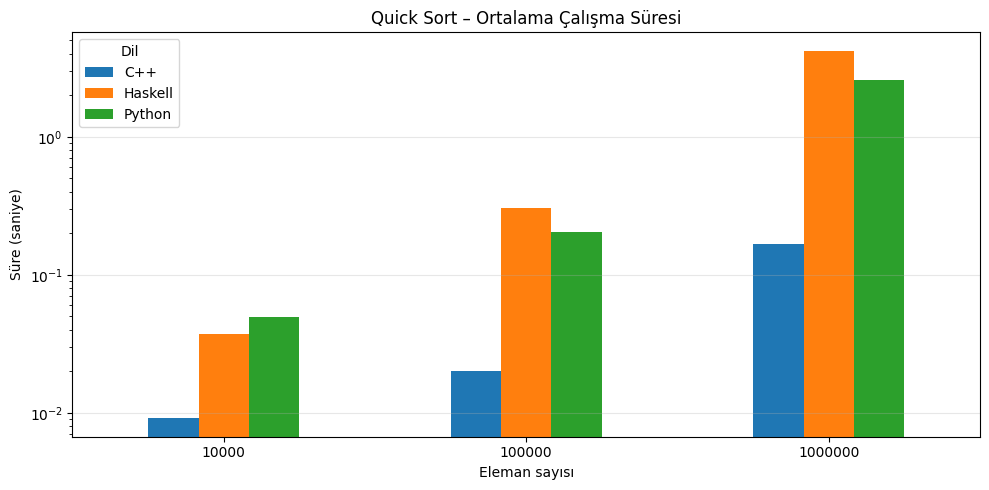

In [8]:
import matplotlib.pyplot as plt

time_pivot = results_df.pivot(
    index="Eleman Sayısı", columns="Dil", values="Ortalama Süre (s)"
)

ax = time_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Quick Sort – Ortalama Çalışma Süresi")
ax.set_xlabel("Eleman sayısı")
ax.set_ylabel("Süre (saniye)")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 10. Genel Sonuç

Quick Sort, böl-ve-yönet yaklaşımıyla çalışan ve ortalama durumda O(n log n) zaman karmaşıklığı sunan etkili bir sıralama algoritmasıdır. Bununla birlikte en kötü durumda O(n²) zaman alabilir. Pivot seçimi  algoritmanın performansını doğrudan etkiler.

Bu çalışmada Quick Sort, Haskell, C++ ve Python dillerinde uygulanmış; aynı veri kümeleri kullanılarak çalışma süresi ve süreç belleği karşılaştırılmıştır. Kesin sonuçlar, notebook'un çalıştırıldığı bilgisayardan alınan ölçüm tablosu ve grafikler üzerinden yorumlanmalıdır. Haskell'in değişmez listelerle, C++'ın yerinde vektör işlemleriyle ve Python'ın liste oluşturma yaklaşımıyla uygulanması, bellek ve hız sonuçlarını etkileyebilecek önemli bir farklılıktır.

Sonuç olarak algoritma analizi yalnızca teorik karmaşıklıkla sınırlı değildir. Gerçek performans; programlama dili, veri yapısı, bellek yönetimi, derleyici/yorumlayıcı ve donanım gibi etkenlerin birlikte değerlendirilmesiyle anlaşılabilir.